# Итоговое сравнение алгоритмов из ЛР1–5

## Цель

В этом ноутбуке я сравниваю результаты KNN, линейных моделей, дерева,
случайного леса и бустинга для покупки страховки и цены ноутбука. Для каждого алгоритма рассматриваются четыре варианта:
библиотечный исходный, библиотечный после подбора, собственный исходный
и собственный после переноса выбранных настроек.

Ноутбук обобщает фактически полученные результаты выполненных ЛР1–5.
Модели здесь не обучаются. Полные CSV метрик сохранены внутри ноутбука,
поэтому для повторного построения таблиц и графиков не нужны
внешние файлы, подключение к GitHub или повторная загрузка данных.

## Условия сравнения

- [Travel Insurance Prediction Data](https://www.kaggle.com/datasets/tejashvi14/travel-insurance-prediction-data): 1987 наблюдений, 8 входных признаков, цель TravelInsurance. Train — 1543 строки, test — 444. Основная метрика — macro-F1, дополнительные — Accuracy, ROC-AUC, precision и recall покупателей.
- [Laptop Prices](https://www.kaggle.com/datasets/owm4096/laptop-prices): 1275 наблюдений, 19 входных признаков, цель Price_euros. Train — 1009 строк, test — 266. Основная метрика — MAE в евро, дополнительные — RMSE и R².

Одинаковые входные профили объединены в группы. Группа целиком
попадает в train или test и в одну проверочную часть CV. Во всех
работах сохранены одни и те же строки test и три групповых фолда CV.
Предобработка обучается внутри Pipeline на обучающих частях.

Параметры выбирались по CV отдельно для каждой задачи, затем
фиксировались до оценки соответствующей модели на тесте.
Здесь выполняется ретроспективное сравнение уже завершённых работ.
Тестовые результаты не используются для нового подбора параметров.

## Окружение

Ниже выводятся версии библиотек, используемых для построения сводки.

In [1]:
# Проверяем окружение для сводных таблиц и графиков.
import sys
import json
import hashlib
import zipfile
from io import StringIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
matplotlib: 3.10.0


## Источники результатов

Таблицы CV и теста взяты из выполненных ЛР1–5. Они встроены в следующую
ячейку без округления. Для отображения округляются только копии таблиц.
Контрольные суммы проверяют, что встроенные данные не изменились.
Также сохранены протокол разбиений и версии исходных ноутбуков.

In [2]:
# Загружаем встроенные результаты, проверяем целостность и структуру.
payload = json.loads(r'''{"sources":[{"lab":1,"algorithm":"KNN","task":"classification","stage":"cv","file":"lab1_four_variants_cv_classification.csv","sha256":"c81941f78c9243997918f71ed0bcd12fce8f7dbcddfe7e17c34f6697d121201b","csv":"model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std\nsklearn baseline,0.7498626300680035,0.01869487904056594,0.7866355501500903,0.014821144334449808,0.792857928377522,0.026868210049767038\nsklearn improved,0.754038871581883,0.022028102587596046,0.7885446116073292,0.018744908532630455,0.7963258922709517,0.028429913186388312\nown baseline,0.7527556272972801,0.018754892506075375,0.7905410274299106,0.010030799861999564,0.7959903887601428,0.03432295645376843\nown improved,0.7563945582229433,0.01933768007273758,0.7918223424966914,0.013784964687632618,0.7976646663931016,0.03405381046453439\n"},{"lab":1,"algorithm":"KNN","task":"classification","stage":"test","file":"lab1_final_test_classification.csv","sha256":"5e84e40a124719f9709a56a255f157a0dceda39ff67c0df0eb129db400d707e0","csv":"model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1\nsklearn baseline,0.015008292999937112,0.012482852000175626,0.010798828000133653,0.7220991815117959,0.7657657657657657,0.7554754424428725,0.7008547008547008,0.543046357615894\nsklearn improved,0.0132637810002052,0.010792580000270391,0.010317274000044563,0.723265012585401,0.7657657657657657,0.7574983613226951,0.6974789915966386,0.5496688741721855\nown baseline,0.05429458899970996,0.35252012099999774,0.39202084199996534,0.717943185904351,0.7612612612612613,0.7546843568474109,0.6890756302521008,0.543046357615894\nown improved,0.020881923000160896,0.6863000049997936,0.6315242460000263,0.7191080977845684,0.7612612612612613,0.7544131275003955,0.6859504132231405,0.5496688741721855\n"},{"lab":1,"algorithm":"KNN","task":"regression","stage":"cv","file":"lab1_four_variants_cv_regression.csv","sha256":"9c9384df59de51ae83a92e8612c1ac55f875798b236b336c0048d183c7198bde","csv":"model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std\nsklearn baseline,265.228014118506,12.180953775256697,416.33954418272543,15.99079911385156,0.6509033944225449,0.022513360027221915\nsklearn improved,226.17437452049558,14.28972700551748,337.04686304210935,24.88300178135794,0.7693695297364996,0.04289348507468814\nown baseline,265.3851427452781,12.046265184565593,416.5948530851469,16.356451745839884,0.6504800856017011,0.02280799847939358\nown improved,226.18540041282645,14.163770851186358,336.97078483173334,24.703565926408228,0.7694954910643373,0.04259958053793951\n"},{"lab":1,"algorithm":"KNN","task":"regression","stage":"test","file":"lab1_final_test_regression.csv","sha256":"6e0a99e04e32881493d097d64b246e90a49f779c58668c84f2bacb394d15f4a7","csv":"model,fit_seconds,predict_seconds,mae,rmse,r2\nsklearn baseline,0.10503751300029762,0.0884590090004167,237.22313533834583,366.27040102821354,0.7099284620146131\nsklearn improved,0.1081040409999332,0.17235933299980388,196.2580582956701,305.63494739588657,0.7980204069874357\nown baseline,0.06643922500006738,0.2716861149997385,237.73968421052632,366.85570093143536,0.7090006529648888\nown improved,0.02471411899978193,0.15431202000036137,196.11750634644022,305.5828491835433,0.7980892595775257\n"},{"lab":2,"algorithm":"Линейные модели","task":"classification","stage":"cv","file":"lab2_four_variants_cv_classification.csv","sha256":"68c96046998a11832a6ff86e6f952386c9f06781bc603d82cb7504e319bfb318","csv":"model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std\nsklearn baseline,0.7163814753249405,0.05371896760106135,0.7653582073012668,0.04566182290215063,0.7577331877162111,0.0389012948311983\nsklearn improved,0.7309657204235739,0.03308213020494709,0.7824224566135388,0.026784004877218062,0.7588318010204592,0.03308778115881468\nown baseline,0.7163814753249405,0.05371896760106135,0.7653582073012668,0.04566182290215063,0.7577457087945466,0.03892900075428678\nown improved,0.7309657204235739,0.03308213020494709,0.7824224566135388,0.026784004877218062,0.75871576466067,0.03316048459048001\n"},{"lab":2,"algorithm":"Линейные модели","task":"classification","stage":"test","file":"lab2_final_test_classification.csv","sha256":"da8a5a59079563437da67df68f5f49989979ec4f25130ed26748c6a58d0d0980","csv":"model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1\nsklearn baseline,0.013515389000076539,0.0038669299999583018,0.003698169000017515,0.6999374711830579,0.759009009009009,0.7520963768279728,0.7291666666666666,0.46357615894039733\nsklearn improved,0.010248579000062819,0.003692398999874058,0.0036335390000203915,0.7103088299260547,0.7702702702702703,0.749519698031327,0.7692307692307693,0.46357615894039733\nown baseline,0.008297588999994332,0.003582739999956175,0.003572500000018408,0.6999374711830579,0.759009009009009,0.7521189792735574,0.7291666666666666,0.46357615894039733\nown improved,0.008713908999880005,0.003619529999923543,0.0035604400000011083,0.7103088299260547,0.7702702702702703,0.7493614809122346,0.7692307692307693,0.46357615894039733\n"},{"lab":2,"algorithm":"Линейные модели","task":"regression","stage":"cv","file":"lab2_four_variants_cv_regression.csv","sha256":"bbc475409967c4b21bd4fa5166e6e9df238d93a1621341b544c41cf48e20eb4a","csv":"model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std\nsklearn baseline,255.7925749450211,20.541546653985844,367.6064753398512,54.026773414187886,0.721283611242654,0.09777360554121886\nsklearn improved,240.76747947561736,7.710689303549626,355.39129079940045,3.2665460248212086,0.7455829381962049,0.010977515139495835\nown baseline,255.79257494502235,20.541546653988064,367.6064753398575,54.02677341419912,0.7212836112426425,0.09777360554123922\nown improved,240.76747947561736,7.710689303549626,355.39129079940045,3.2665460248212086,0.7455829381962049,0.010977515139495835\n"},{"lab":2,"algorithm":"Линейные модели","task":"regression","stage":"test","file":"lab2_final_test_regression.csv","sha256":"c3b8802e28f63065757c323b6c021ce26b601ef064046a306278604ad49eb791","csv":"model,fit_seconds,predict_seconds,mae,rmse,r2\nsklearn baseline,0.013892309000084424,0.005516968999927485,248.62093218037862,341.57895339197677,0.7477195036859703\nsklearn improved,0.08253999300018222,0.006444858999884673,264.30957016613445,574.5573239941418,0.28621371362314096\nown baseline,0.014989849000130562,0.005337579000070036,248.62093218037862,341.5789533919767,0.7477195036859705\nown improved,0.013969508999934988,0.00554079899984572,264.30957016613445,574.5573239941418,0.28621371362314096\n"},{"lab":3,"algorithm":"Дерево","task":"classification","stage":"cv","file":"lab3_cv_classification.csv","sha256":"7d54b34fe5642cc902d0f846aff5987cc5a92af6fd273ca5372001915c6aa430","csv":"model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std\nsklearn baseline,0.7350878939693258,0.03409076671091537,0.7635289080159194,0.028799634908266716,0.7457753073439873,0.05046227336730777\nsklearn improved,0.8001133701534981,0.035956823827010834,0.8329467825420779,0.023885085206572523,0.7998121028457611,0.034979794536476184\nown baseline,0.737374002942916,0.03397695866231602,0.7661317944310334,0.031770815499554496,0.7498864220109206,0.045854731610748024\nown improved,0.8001133701534981,0.035956823827010834,0.8329467825420779,0.023885085206572523,0.7998121028457611,0.034979794536476184\n"},{"lab":3,"algorithm":"Дерево","task":"classification","stage":"test","file":"lab3_final_test_classification.csv","sha256":"b2d14d5f928a5d9170189502e38d497a5f0fb8e82dd5eb67bd38ea2b1c5e0358","csv":"model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1\nsklearn baseline,0.00918661000002885,0.0033796319999623847,0.003137085999981082,0.7194223332772904,0.7545045045045045,0.7279569649436068,0.6544117647058824,0.5894039735099338\nsklearn improved,0.006955514000026142,0.003149908000011692,0.0029884589999937816,0.7750485804254555,0.8220720720720721,0.7693194403634472,0.9,0.5364238410596026\nown baseline,0.21710892999999487,0.004775811000001795,0.004150132000006579,0.7204551814196436,0.7567567567567568,0.7221707388739462,0.6616541353383458,0.5827814569536424\nown improved,0.030474415000014687,0.00481181300000344,0.0045036270000196055,0.7750485804254555,0.8220720720720721,0.7693194403634472,0.9,0.5364238410596026\n"},{"lab":3,"algorithm":"Дерево","task":"regression","stage":"cv","file":"lab3_cv_regression.csv","sha256":"ebf9d91b8c8e2cd25dd83e042241c9f8e802facb0ace46a1ec6eeaa6c6e210d1","csv":"model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std\nsklearn baseline,259.8889678467414,12.54136952076186,391.17058920233154,27.611712811472394,0.6915462174628253,0.03599628081992422\nsklearn improved,251.15238813521765,16.041525617982458,380.9397027071184,29.865138148947494,0.7055767366822178,0.05348979670112216\nown baseline,258.3968007228031,8.146713751141188,393.4195668153969,24.66423146700063,0.6879017627114773,0.03440422473659675\nown improved,251.1523881352176,16.04152561798246,380.9397027071184,29.865138148947484,0.7055767366822178,0.05348979670112216\n"},{"lab":3,"algorithm":"Дерево","task":"regression","stage":"test","file":"lab3_final_test_regression.csv","sha256":"cb1de9aecb26b6112847830dd655a518d3b023a7ff278b4cfeff0b0c036bd67f","csv":"model,fit_seconds,predict_seconds,mae,rmse,r2\nsklearn baseline,0.01743055099996127,0.004987673000016457,222.19046992481202,331.2093486920263,0.762804392113077\nsklearn improved,0.012291537999999491,0.004851527999960581,208.76020496640533,297.51071388796464,0.8086155317537442\nown baseline,1.3135963009999614,0.006102092999981323,226.93787593984962,332.3718945638434,0.7611363551515417\nown improved,0.1478182019999963,0.005587912000009965,208.33742204756976,297.38733505862274,0.808774234579471\n"},{"lab":4,"algorithm":"Случайный лес","task":"classification","stage":"cv","file":"lab4_cv_classification.csv","sha256":"00114300621a7e2ae767534e79519ab21df9de4a78fe49c7c22de6e176983131","csv":"model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std\nsklearn baseline,0.7844539978957714,0.023912674567506804,0.8123317702905067,0.021440377323577255,0.8111001172765976,0.039506912349344\nsklearn improved,0.803112222342186,0.034260637630307504,0.8361956454400635,0.023631169706598506,0.8228434752821832,0.04378831818159485\nown baseline,0.7768982368554121,0.015455795431232761,0.8053787115204628,0.014119813319638293,0.8089666736955282,0.04073220396265378\nown improved,0.803112222342186,0.034260637630307504,0.8361956454400635,0.023631169706598506,0.8222156383534017,0.04636927756654948\n"},{"lab":4,"algorithm":"Случайный лес","task":"classification","stage":"test","file":"lab4_final_test_classification.csv","sha256":"590226f5491f2b5a3f5e9642dec37647ca6fdf28d12351ac61458471e6b8250f","csv":"model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1\nsklearn baseline,0.2589103749999708,0.017056249000006574,0.01644220100001803,0.7498285154336111,0.7927927927927928,0.746264945867143,0.7706422018348624,0.5562913907284768\nsklearn improved,0.23869969700001548,0.014710580999974354,0.014239551000002848,0.7773447170470054,0.8220720720720721,0.7564812512713875,0.8829787234042553,0.5496688741721855\nown baseline,11.624948684999993,0.3169573950000313,0.3094284829999765,0.7508494329919158,0.795045045045045,0.7378229324412902,0.7830188679245284,0.5496688741721855\nown improved,2.305697043000009,0.07891034800002217,0.055479466000008415,0.7773447170470054,0.8220720720720721,0.7559839974685262,0.8829787234042553,0.5496688741721855\n"},{"lab":4,"algorithm":"Случайный лес","task":"regression","stage":"cv","file":"lab4_cv_regression.csv","sha256":"4c07c60799fd4298369a38dc75a602b4975374a48340b6bdc1d35c5ce09f9089","csv":"model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std\nsklearn baseline,197.94217747471828,10.272547951239652,297.18386485222146,18.517313516555866,0.8209382859792632,0.03029089811825607\nsklearn improved,197.15096139542132,11.29650379446647,296.22441811017717,20.403402190670565,0.8219117925286515,0.032560612623711856\nown baseline,197.80986624846358,9.89502493191179,297.0057985961632,18.69873912807797,0.8211516250806143,0.03022863994652259\nown improved,194.51959346523347,7.8602604813794255,292.2317021372432,17.47722580175019,0.8269021126071897,0.028719214114878034\n"},{"lab":4,"algorithm":"Случайный лес","task":"regression","stage":"test","file":"lab4_final_test_regression.csv","sha256":"100b7d6ea8695aa1205d933ec3b329cd24d603d9bb4c96559ee01fdd2ffb697c","csv":"model,fit_seconds,predict_seconds,mae,rmse,r2\nsklearn baseline,0.7943299430000366,0.0208345979999649,181.06990055227357,271.52207551587463,0.8405913957609934\nsklearn improved,0.531238793,0.020084540000027573,176.30544150375943,266.0526569891043,0.8469488241159612\nown baseline,18.129434950000018,0.25851516299997,178.76349458109564,265.79101641492275,0.8472497022040033\nown improved,22.066230618999953,0.29302004899994927,178.2186110007161,272.19160498463964,0.8398042748918945\n"},{"lab":5,"algorithm":"Бустинг","task":"classification","stage":"cv","file":"lab5_cv_classification.csv","sha256":"2188f85bae7428cc3095303860b908e4989f2b846b7fd44ed26206fb4c9cd1c9","csv":"model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std\nsklearn baseline,0.7921528657355698,0.02883119966981728,0.8253515433858873,0.015185933343034311,0.8247576626442031,0.037004508772296614\nsklearn improved,0.8040577285242714,0.03434441264925435,0.8375096245949459,0.02253063719173789,0.8074988925023675,0.05811339794348478\nown baseline,0.793096873853063,0.027887408391668953,0.8260195460578981,0.014157103837309316,0.8238950803537834,0.03749936847307081\nown improved,0.8040577285242714,0.03434441264925435,0.8375096245949459,0.02253063719173789,0.8074988925023675,0.05811339794348478\n"},{"lab":5,"algorithm":"Бустинг","task":"classification","stage":"test","file":"lab5_final_test_classification.csv","sha256":"6cff1c743e15dbc17be9e9f4097e934bcb93c22ce0831e542f6ca953461b60d7","csv":"model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1\nsklearn baseline,0.2066232980000109,0.005836702999999943,0.005359069000007821,0.7750930780335841,0.8198198198198198,0.7654770246140633,0.8736842105263158,0.5496688741721855\nsklearn improved,0.17366293599997107,0.005539107000004151,0.005205525000008038,0.7818738635276103,0.8265765765765766,0.7782022014782,0.9021739130434783,0.5496688741721855\nown baseline,0.6134206959999915,0.0119587739999929,0.011057632000017747,0.7750930780335841,0.8198198198198198,0.7654770246140633,0.8736842105263158,0.5496688741721855\nown improved,0.39808455100001083,0.008392556000046625,0.008751587000006111,0.7818738635276103,0.8265765765765766,0.7782022014782,0.9021739130434783,0.5496688741721855\n"},{"lab":5,"algorithm":"Бустинг","task":"regression","stage":"cv","file":"lab5_cv_regression.csv","sha256":"cb4fffcd20a77bce033c16c945f6988f4f0e366d77525ea9237da371a85e3b78","csv":"model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std\nsklearn baseline,202.02308114723647,9.44338729043392,295.6587604673073,25.647805336361426,0.8220522127030936,0.03912385283242692\nsklearn improved,195.39079930199753,14.049431442506318,287.7310918640034,32.7535613405305,0.8306086456851814,0.04561837437220686\nown baseline,203.02151611388635,8.586472804606252,295.3094692272942,24.1347355628404,0.8226137527506698,0.03758971646628691\nown improved,195.55662497397373,13.546771539628793,287.58394693450225,30.76944788022386,0.8309996136918038,0.04369334748631098\n"},{"lab":5,"algorithm":"Бустинг","task":"regression","stage":"test","file":"lab5_final_test_regression.csv","sha256":"68ed331b981e9430f42fa1643d318676272ca52d82b6287abee0a5d14c2c4e37","csv":"model,fit_seconds,predict_seconds,mae,rmse,r2\nsklearn baseline,0.24549234699998124,0.00734577299999728,192.9648243389047,271.64445155735916,0.8404476712402738\nsklearn improved,0.5137995530000126,0.016216419999977916,182.11566042004458,259.9001095659723,0.8539456841038375\nown baseline,2.612934229000018,0.018816653999977007,192.648731127261,270.81698854092747,0.841418223520589\nown improved,4.650650000999974,0.01728737300004468,181.98992702390288,258.8388134124401,0.8551360675968915\n"}],"notebooks":[{"file":"lab1_knn.ipynb","sha256":"7e4a9219473108ead1b33b98b545b1f0578c1a9c71e4aa405522d1ab86305e45"},{"file":"lab2_linear.ipynb","sha256":"5e7e64f4edd83be96f562960d31c675477bb3b3a350b3d68652d7580adc3ad13"},{"file":"lab3_tree.ipynb","sha256":"0527e628e1bebf38127117455ce0a655d24a36b0c267a16b3577003e33402b93"},{"file":"lab4_forest.ipynb","sha256":"4b65cc63ae895bd9db95922788ecfe7f19edce47df7fadce5cb8fd4ed071f3e7"},{"file":"lab5_boosting.ipynb","sha256":"cf8b2932d7df0b712cb50cba0681784151bfba984243c0624967924d9018bbc4"}],"protocol":{"random_state":42,"classification_split":{"method":"StratifiedGroupKFold","n_splits":5,"test_fold":0},"regression_split":{"method":"GroupShuffleSplit","test_size_groups":0.2},"classification_features":["Age","Employment Type","GraduateOrNot","AnnualIncome","FamilyMembers","ChronicDiseases","FrequentFlyer","EverTravelledAbroad"],"regression_features":["Company","TypeName","Inches","Ram","OS","Weight","Screen","ScreenW","ScreenH","Touchscreen","IPSpanel","RetinaDisplay","CPU_company","CPU_freq","PrimaryStorage","SecondaryStorage","PrimaryStorageType","SecondaryStorageType","GPU_company"],"versions":{"python":"3.13.18","numpy":"2.4.6","pandas":"2.2.3","sklearn":"1.6.1"},"source_sha256":{"TravelInsurancePrediction.csv":"26c79f34d14138771983be3dc2dbf019c6e8b20d78db9109261149dec63da426","laptop_prices.csv":"3638d6dc2c50b89263c99b364173a1f773e0b1fb0b83aa080749e95b7a77da8d"}},"fingerprints":{"travel":{"test_mask_sha256":"26baec97124eb0502e188b8451b25f110001b8c5d7c7ef7e0391b2982f09e97d","cv_assignment_sha256":"96aebde84f18d8298cb2013035e3499b7c42e5103e5b95d8b337f7afb125d321"},"laptops":{"test_mask_sha256":"88fed4bc26da4cdd5bf8d6edb965a0e27322070907a2b50ab0017abc9cb97b3d","cv_assignment_sha256":"68661b03ff5b016ab29e97c79596e6f67bedd74821bd782b3b9943f27edb7f45"}}}''')
expected_models = {"sklearn baseline", "sklearn improved", "own baseline", "own improved"}
collected = {("cv", "classification"): [], ("cv", "regression"): [],
             ("test", "classification"): [], ("test", "regression"): []}
source_rows = []
for item in payload["sources"]:
    assert hashlib.sha256(item["csv"].encode("utf-8")).hexdigest() == item["sha256"]
    table = pd.read_csv(StringIO(item["csv"]))
    assert len(table) == 4 and set(table["model"]) == expected_models
    assert table["model"].is_unique
    numeric = table.select_dtypes(include="number")
    assert not numeric.isna().any().any() and np.isfinite(numeric.to_numpy()).all()
    table.insert(0, "algorithm", item["algorithm"])
    table.insert(0, "lab", item["lab"])
    table["implementation"] = table["model"].str.split().str[0]
    table["variant"] = table["model"].str.split().str[1]
    collected[(item["stage"], item["task"])].append(table)
    source_rows.append({key: item[key] for key in ["lab", "task", "stage", "file", "sha256"]})

frames = {key: pd.concat(tables, ignore_index=True) for key, tables in collected.items()}
for table in frames.values():
    assert len(table) == 20 and not table.duplicated(["lab", "model"]).any()
source_manifest = pd.DataFrame(source_rows)
algorithm_order = ["KNN", "Линейные модели", "Дерево", "Случайный лес", "Бустинг"]
variant_order = ["sklearn baseline", "sklearn improved", "own baseline", "own improved"]
results_dir = Path("/content/results/lab6")
figure_dir = results_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
print("Проверено CSV:", len(source_manifest))
print("Вариантов в каждой задаче и каждом этапе:", len(frames[("test", "classification")]))
display(pd.DataFrame([
    {"task": "Страховка", "train": 1543, "test": 444, "cv_folds": 3},
    {"task": "Ноутбуки", "train": 1009, "test": 266, "cv_folds": 3},
]))

Проверено CSV: 20
Вариантов в каждой задаче и каждом этапе: 20


,task,train,test,cv_folds
0,Страховка,1543,444,3
1,Ноутбуки,1009,266,3


## Сравнение на кросс-валидации

Показаны средние метрики и выборочные стандартные отклонения по трём
фолдам. Разброс по фолдам не является доверительным интервалом.
У выбранных настроек эти же части CV участвовали в подборе,
поэтому их оценка может быть оптимистичной.

Полные таблицы сохраняют все четыре варианта каждого алгоритма.
Для macro-F1, Accuracy, ROC-AUC и R² большее значение лучше;
для MAE и RMSE — меньшее.

In [3]:
# Объединяем результаты CV всех алгоритмов без повторного обучения.
cv_cls = frames[("cv", "classification")]
cv_reg = frames[("cv", "regression")]
cv_columns_cls = ["algorithm", "model", "macro_f1_mean", "macro_f1_std",
                  "accuracy_mean", "accuracy_std", "roc_auc_mean", "roc_auc_std"]
cv_columns_reg = ["algorithm", "model", "mae_mean", "mae_std",
                  "rmse_mean", "rmse_std", "r2_mean", "r2_std"]
print("Классификация: все варианты на CV")
display(cv_cls[cv_columns_cls].round(4))
print("Регрессия: все варианты на CV")
display(cv_reg[cv_columns_reg].round(4))

Классификация: все варианты на CV


,algorithm,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,KNN,sklearn baseline,0.7499,0.0187,0.7866,0.0148,0.7929,0.0269
1,KNN,sklearn improved,0.7540,0.0220,0.7885,0.0187,0.7963,0.0284
2,KNN,own baseline,0.7528,0.0188,0.7905,0.0100,0.7960,0.0343
3,KNN,own improved,0.7564,0.0193,0.7918,0.0138,0.7977,0.0341
4,Линейные модели,sklearn baseline,0.7164,0.0537,0.7654,0.0457,0.7577,0.0389
5,Линейные модели,sklearn improved,0.7310,0.0331,0.7824,0.0268,0.7588,0.0331
6,Линейные модели,own baseline,0.7164,0.0537,0.7654,0.0457,0.7577,0.0389
7,Линейные модели,own improved,0.7310,0.0331,0.7824,0.0268,0.7587,0.0332
8,Дерево,sklearn baseline,0.7351,0.0341,0.7635,0.0288,0.7458,0.0505
9,Дерево,sklearn improved,0.8001,0.0360,0.8329,0.0239,0.7998,0.0350


Регрессия: все варианты на CV


,algorithm,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,KNN,sklearn baseline,265.2280,12.1810,416.3395,15.9908,0.6509,0.0225
1,KNN,sklearn improved,226.1744,14.2897,337.0469,24.8830,0.7694,0.0429
2,KNN,own baseline,265.3851,12.0463,416.5949,16.3565,0.6505,0.0228
3,KNN,own improved,226.1854,14.1638,336.9708,24.7036,0.7695,0.0426
4,Линейные модели,sklearn baseline,255.7926,20.5415,367.6065,54.0268,0.7213,0.0978
5,Линейные модели,sklearn improved,240.7675,7.7107,355.3913,3.2665,0.7456,0.0110
6,Линейные модели,own baseline,255.7926,20.5415,367.6065,54.0268,0.7213,0.0978
7,Линейные модели,own improved,240.7675,7.7107,355.3913,3.2665,0.7456,0.0110
8,Дерево,sklearn baseline,259.8890,12.5414,391.1706,27.6117,0.6915,0.0360
9,Дерево,sklearn improved,251.1524,16.0415,380.9397,29.8651,0.7056,0.0535


## Выбранные варианты: CV и тест рядом

Здесь оставлены варианты improved — настройки, выбранные по CV.
Название не гарантирует улучшения на тесте: в ЛР2 выбранный
регрессор оказался хуже исходного.

По сохранённым результатам я проверяю, какой алгоритм был бы выбран
по средней основной метрике CV. Библиотечные и собственные реализации
сравниваю отдельно. Это сравнение завершённых экспериментов,
а не новый подбор после просмотра теста.

In [4]:
# Сопоставляем CV и test по ключу алгоритм + вариант модели.
test_cls = frames[("test", "classification")]
test_reg = frames[("test", "regression")]
summaries = {}
cv_choices = []
for task, cv, test, metric in [
    ("classification", cv_cls, test_cls, "macro_f1"),
    ("regression", cv_reg, test_reg, "mae"),
]:
    selected = cv[cv["variant"] == "improved"].merge(
        test[["lab", "model", metric]], on=["lab", "model"], validate="one_to_one",
    )
    columns = ["algorithm", "implementation", metric + "_mean", metric + "_std", metric]
    summaries[task] = selected[columns].copy()
    print(task + ": выбранные варианты; среднее CV, разброс CV и test")
    display(summaries[task].round(4))
    for implementation, group in selected.groupby("implementation", sort=False):
        position = group[metric + "_mean"].idxmax() if task == "classification" else group[metric + "_mean"].idxmin()
        best = selected.loc[position]
        cv_choices.append({"task": task, "implementation": implementation,
                           "algorithm_by_cv": best["algorithm"], "metric": metric,
                           "cv_mean": best[metric + "_mean"], "test": best[metric]})
cv_choice_table = pd.DataFrame(cv_choices)
print("Ретроспективное правило выбора по CV")
display(cv_choice_table.round(4))

classification: выбранные варианты; среднее CV, разброс CV и test


,algorithm,implementation,macro_f1_mean,macro_f1_std,macro_f1
0,KNN,sklearn,0.7540,0.0220,0.7233
1,KNN,own,0.7564,0.0193,0.7191
2,Линейные модели,sklearn,0.7310,0.0331,0.7103
3,Линейные модели,own,0.7310,0.0331,0.7103
4,Дерево,sklearn,0.8001,0.0360,0.7750
5,Дерево,own,0.8001,0.0360,0.7750
6,Случайный лес,sklearn,0.8031,0.0343,0.7773
7,Случайный лес,own,0.8031,0.0343,0.7773
8,Бустинг,sklearn,0.8041,0.0343,0.7819
9,Бустинг,own,0.8041,0.0343,0.7819


regression: выбранные варианты; среднее CV, разброс CV и test


,algorithm,implementation,mae_mean,mae_std,mae
0,KNN,sklearn,226.1744,14.2897,196.2581
1,KNN,own,226.1854,14.1638,196.1175
2,Линейные модели,sklearn,240.7675,7.7107,264.3096
3,Линейные модели,own,240.7675,7.7107,264.3096
4,Дерево,sklearn,251.1524,16.0415,208.7602
5,Дерево,own,251.1524,16.0415,208.3374
6,Случайный лес,sklearn,197.1510,11.2965,176.3054
7,Случайный лес,own,194.5196,7.8603,178.2186
8,Бустинг,sklearn,195.3908,14.0494,182.1157
9,Бустинг,own,195.5566,13.5468,181.9899


Ретроспективное правило выбора по CV


,task,implementation,algorithm_by_cv,metric,cv_mean,test
0,classification,sklearn,Бустинг,macro_f1,0.8041,0.7819
1,classification,own,Бустинг,macro_f1,0.8041,0.7819
2,regression,sklearn,Бустинг,mae,195.3908,182.1157
3,regression,own,Случайный лес,mae,194.5196,178.2186


## Итоговые метрики на тесте

Ниже приведены результаты всех двадцати вариантов для каждой задачи.
Классификацию следует оценивать вместе с precision и recall покупателей:
высокая доля правильных положительных ответов не означает, что найдены
все покупатели. Для регрессии MAE рассматривается вместе с RMSE и R²,
чтобы учитывать крупные промахи.

Отдельная таблица показывает изменение основной метрики после настройки.
Положительное Δmacro-F1 и положительный процент снижения MAE означают
улучшение; отрицательные значения — ухудшение.

In [5]:
# Показываем все тестовые метрики и эффект переноса настроек.
test_columns_cls = ["algorithm", "model", "macro_f1", "accuracy", "roc_auc", "precision_1", "recall_1"]
test_columns_reg = ["algorithm", "model", "mae", "rmse", "r2"]
print("Классификация: все варианты на тесте")
display(test_cls[test_columns_cls].round(4))
print("Регрессия: все варианты на тесте")
display(test_reg[test_columns_reg].round(4))
change_rows = []
for algorithm in algorithm_order:
    row = {"algorithm": algorithm}
    for implementation in ["sklearn", "own"]:
        cls = test_cls[(test_cls["algorithm"] == algorithm) & (test_cls["implementation"] == implementation)].set_index("variant")
        reg = test_reg[(test_reg["algorithm"] == algorithm) & (test_reg["implementation"] == implementation)].set_index("variant")
        row[implementation + " delta_macro_f1"] = cls.loc["improved", "macro_f1"] - cls.loc["baseline", "macro_f1"]
        row[implementation + " mae_reduction_pct"] = 100 * (reg.loc["baseline", "mae"] - reg.loc["improved", "mae"]) / reg.loc["baseline", "mae"]
    change_rows.append(row)
change_table = pd.DataFrame(change_rows)
print("Изменение основной метрики после настройки")
display(change_table.round(4))

Классификация: все варианты на тесте


,algorithm,model,macro_f1,accuracy,roc_auc,precision_1,recall_1
0,KNN,sklearn baseline,0.7221,0.7658,0.7555,0.7009,0.5430
1,KNN,sklearn improved,0.7233,0.7658,0.7575,0.6975,0.5497
2,KNN,own baseline,0.7179,0.7613,0.7547,0.6891,0.5430
3,KNN,own improved,0.7191,0.7613,0.7544,0.6860,0.5497
4,Линейные модели,sklearn baseline,0.6999,0.7590,0.7521,0.7292,0.4636
5,Линейные модели,sklearn improved,0.7103,0.7703,0.7495,0.7692,0.4636
6,Линейные модели,own baseline,0.6999,0.7590,0.7521,0.7292,0.4636
7,Линейные модели,own improved,0.7103,0.7703,0.7494,0.7692,0.4636
8,Дерево,sklearn baseline,0.7194,0.7545,0.7280,0.6544,0.5894
9,Дерево,sklearn improved,0.7750,0.8221,0.7693,0.9000,0.5364


Регрессия: все варианты на тесте


,algorithm,model,mae,rmse,r2
0,KNN,sklearn baseline,237.2231,366.2704,0.7099
1,KNN,sklearn improved,196.2581,305.6349,0.7980
2,KNN,own baseline,237.7397,366.8557,0.7090
3,KNN,own improved,196.1175,305.5828,0.7981
4,Линейные модели,sklearn baseline,248.6209,341.5790,0.7477
5,Линейные модели,sklearn improved,264.3096,574.5573,0.2862
6,Линейные модели,own baseline,248.6209,341.5790,0.7477
7,Линейные модели,own improved,264.3096,574.5573,0.2862
8,Дерево,sklearn baseline,222.1905,331.2093,0.7628
9,Дерево,sklearn improved,208.7602,297.5107,0.8086


Изменение основной метрики после настройки


,algorithm,sklearn delta_macro_f1,sklearn mae_reduction_pct,own delta_macro_f1,own mae_reduction_pct
0,KNN,0.0012,17.2686,0.0012,17.5075
1,Линейные модели,0.0104,-6.3103,0.0104,-6.3103
2,Дерево,0.0556,6.0445,0.0546,8.1963
3,Случайный лес,0.0275,2.6313,0.0265,0.3048
4,Бустинг,0.0068,5.6224,0.0068,5.5328


## Графическое сравнение качества

На первом рисунке сопоставлены исходные и выбранные варианты
для каждой реализации. На втором среднее CV с разбросом по фолдам
показано рядом с итоговой оценкой теста для вариантов improved.
Тестовые точки не имеют оценки неопределённости; перекрытие или
неперекрытие линий не является тестом статистической значимости.

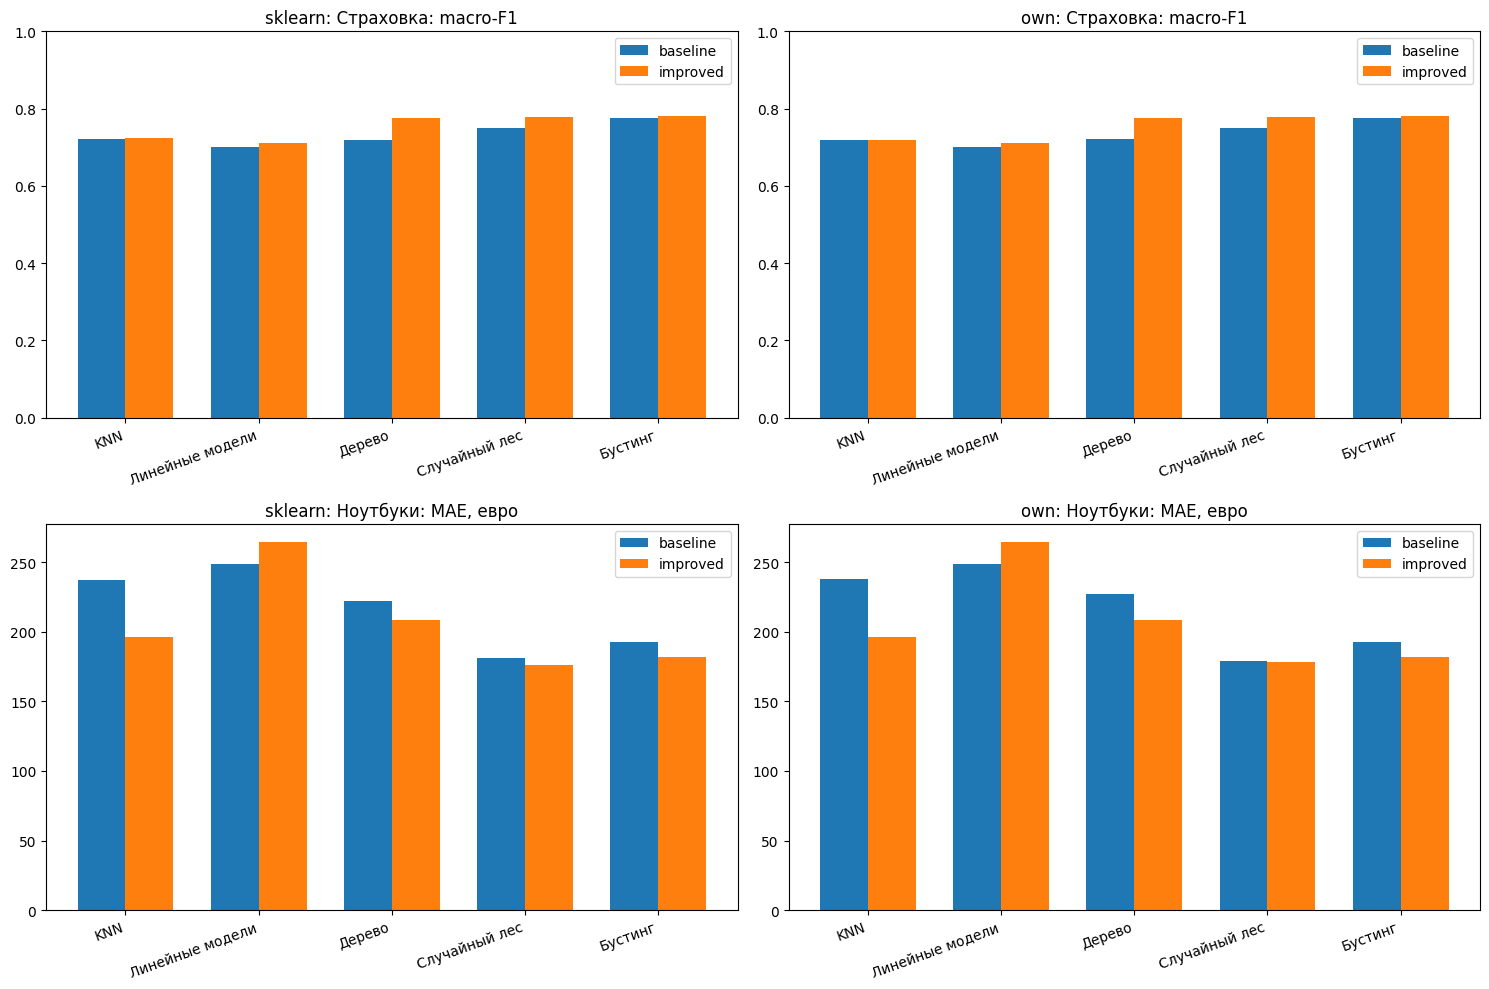

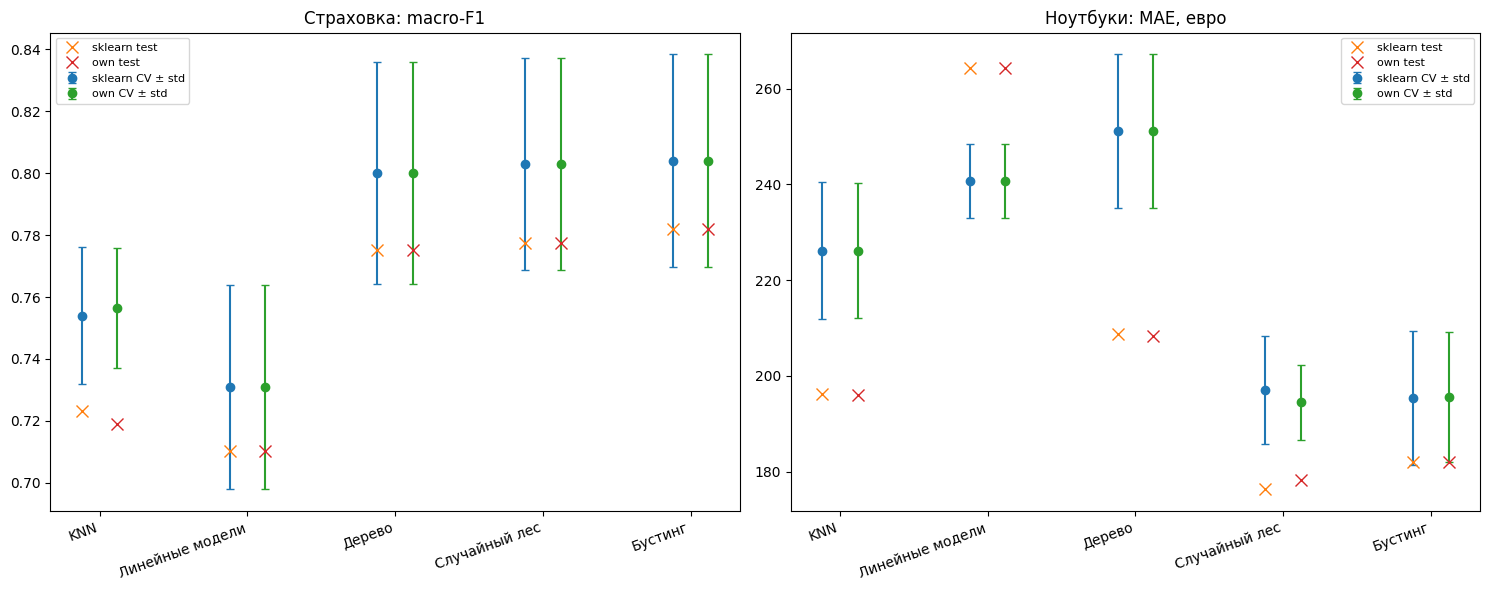

In [6]:
# Строим сравнение качества и разницы между CV и test.
x = np.arange(len(algorithm_order))
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for column, implementation in enumerate(["sklearn", "own"]):
    for row, (table, metric, title) in enumerate([
        (test_cls, "macro_f1", "Страховка: macro-F1"),
        (test_reg, "mae", "Ноутбуки: MAE, евро"),
    ]):
        ax = axes[row, column]
        for offset, variant in [(-0.18, "baseline"), (0.18, "improved")]:
            values = table[(table["implementation"] == implementation) & (table["variant"] == variant)].set_index("algorithm").loc[algorithm_order, metric]
            ax.bar(x + offset, values, width=0.36, label=variant)
        ax.set_xticks(x, algorithm_order, rotation=20, ha="right")
        ax.set_title(implementation + ": " + title)
        if metric == "macro_f1":
            ax.set_ylim(0, 1)
        ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "lab6_test_quality.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, task, metric, title in [
    (axes[0], "classification", "macro_f1", "Страховка: macro-F1"),
    (axes[1], "regression", "mae", "Ноутбуки: MAE, евро"),
]:
    for implementation, shift in [("sklearn", -0.12), ("own", 0.12)]:
        table = summaries[task].query("implementation == @implementation").set_index("algorithm").loc[algorithm_order]
        ax.errorbar(x + shift, table[metric + "_mean"], yerr=table[metric + "_std"],
                    fmt="o", capsize=3, label=implementation + " CV ± std")
        ax.plot(x + shift, table[metric], "x", markersize=8, label=implementation + " test")
    ax.set_xticks(x, algorithm_order, rotation=20, ha="right")
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figure_dir / "lab6_cv_test.png", dpi=150, bbox_inches="tight")
plt.show()

## Время обучения и прогноза

Все измерения относятся к одному запуску и включают предобработку.
predict_proba измерялось отдельно от predict. Замеры разных работ
получены в разных сеансах Colab, без фиксации оборудования и повторных
замеров. Поэтому они показывают порядок величин и ограничения
собственных реализаций, но не дают строгого рейтинга быстродействия.

На графике показаны варианты improved. Использована логарифмическая
шкала времени, чтобы были видны различия порядка величины.

,task,algorithm,implementation,fit_seconds,predict_seconds,predict_proba_seconds
0,classification,KNN,sklearn,0.01326,0.01079,0.01032
1,classification,KNN,own,0.02088,0.68630,0.63152
2,classification,Линейные модели,sklearn,0.01025,0.00369,0.00363
3,classification,Линейные модели,own,0.00871,0.00362,0.00356
4,classification,Дерево,sklearn,0.00696,0.00315,0.00299
5,classification,Дерево,own,0.03047,0.00481,0.0045
6,classification,Случайный лес,sklearn,0.23870,0.01471,0.01424
7,classification,Случайный лес,own,2.30570,0.07891,0.05548
8,classification,Бустинг,sklearn,0.17366,0.00554,0.00521
9,classification,Бустинг,own,0.39808,0.00839,0.00875


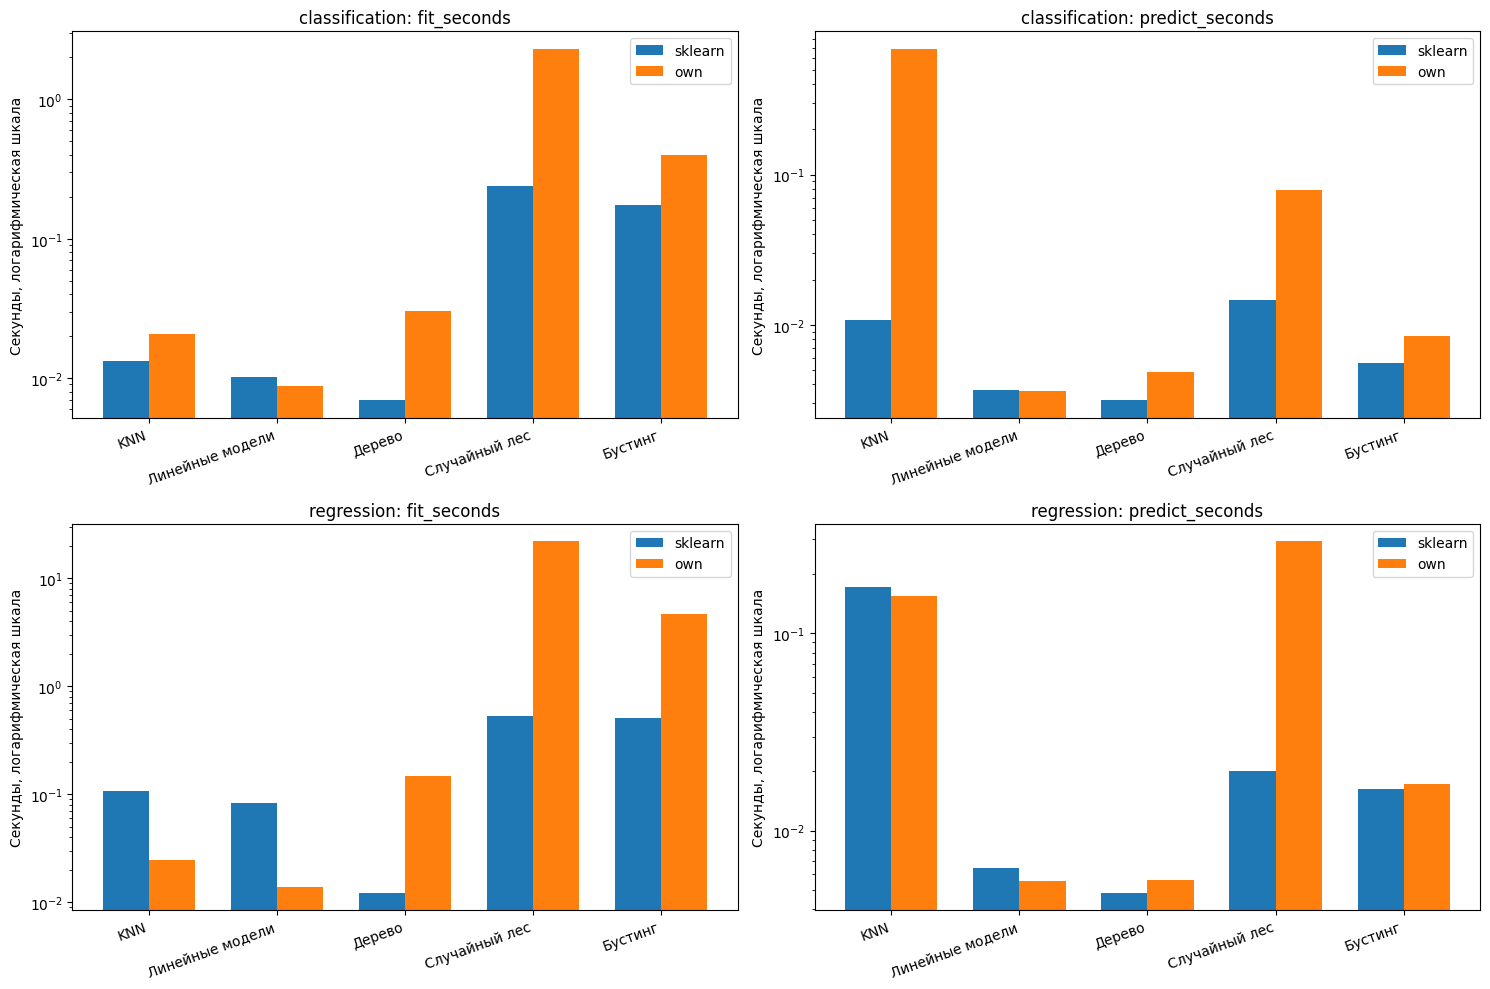

In [7]:
# Сводим измеренные времена; не выполняем новый бенчмарк.
timing_parts = []
for task, table in [("classification", test_cls), ("regression", test_reg)]:
    selected = table[table["variant"] == "improved"].copy()
    selected.insert(0, "task", task)
    columns = ["task", "algorithm", "implementation", "fit_seconds", "predict_seconds"]
    if task == "classification":
        columns.append("predict_proba_seconds")
    timing_parts.append(selected[columns])
timing_table = pd.concat(timing_parts, ignore_index=True)
display(timing_table.round(5).fillna("—"))
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for row, task in enumerate(["classification", "regression"]):
    for column, metric in enumerate(["fit_seconds", "predict_seconds"]):
        ax = axes[row, column]
        for shift, implementation in [(-0.18, "sklearn"), (0.18, "own")]:
            values = timing_table[(timing_table["task"] == task) & (timing_table["implementation"] == implementation)].set_index("algorithm").loc[algorithm_order, metric]
            assert (values > 0).all()
            ax.bar(x + shift, values, width=0.36, label=implementation)
        ax.set_yscale("log")
        ax.set_xticks(x, algorithm_order, rotation=20, ha="right")
        ax.set_title(task + ": " + metric)
        ax.set_ylabel("Секунды, логарифмическая шкала")
        ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "lab6_timing.png", dpi=150, bbox_inches="tight")
plt.show()

## Выводы

1. На этом тесте максимальный macro-F1 получили настроенные классификаторы бустинга: 0.7819. Рядом находятся случайный лес с 0.7773 и дерево с 0.7750. Малые различия на одной выборке не доказывают устойчивого превосходства алгоритма.
2. Среди настроенных библиотечных регрессоров минимальная тестовая MAE у случайного леса — 176.31 евро, у бустинга — 182.12 евро. Среди собственных вариантов также ниже MAE у леса — 178.22 евро против 181.99 евро у бустинга. При этом настроенный собственный бустинг имеет меньшую RMSE: 258.84 евро против 272.19 евро у настроенного собственного леса. Ранжирование зависит от выбранной метрики.
3. По среднему CV среди настроенных библиотечных моделей правило выбора даёт бустинг для обеих задач. Среди собственных моделей это бустинг для классификации и лес для регрессии. Результаты близки и получены на одном разбиении. По тесту MAE леса оказалась ниже, но я не использую это для повторного подбора параметров.
4. Настройка не гарантировала улучшения. В ЛР2 Ridge с логарифмом цены улучшил MAE на CV, но ухудшил её на тесте: 248.62 → 264.31 евро. Большой промах на конфигурации с 64 ГБ RAM подробно разобран в ЛР2. В ЛР4 у собственного леса MAE немного уменьшилась, а RMSE выросла. Отрицательные результаты сохранены в сравнении.
5. Собственные реализации в целом близки по качеству к sklearn, но их прогнозы и скорость не обязаны совпадать. Причины различий включают равнозначные разделения деревьев, случайный выбор признаков и точность вычислений. У KNN важен также выбор соседей на одинаковых расстояниях. Проверки собственных алгоритмов приведены в соответствующих работах.
6. Классификаторы после настройки находят примерно половину покупателей: recall положительного класса находится примерно между 0.46 и 0.55. Высокий precision бустинга 0.9022 не устраняет пропуски. Для практического применения потребовалось бы отдельно задать стоимость ошибок и проверить порог на обучающих данных; в этих работах порог по тесту не подбирался.
7. Тест общий для всех работ, выборки невелики, данные ноутбуков относятся к исходным историческим ценам. Нет оценки на новых периодах, повторных seed или статистической проверки различий. Полученные результаты характеризуют эти наборы и протокол, а не гарантируют качество при внедрении.

## Сохранение сводки

Следующая ячейка сохраняет полные таблицы, графики, источники метрик
и их контрольные суммы в архив. Исходные данные и модели заново
не загружаются и не обучаются.

In [8]:
# Сохраняем сводные результаты и скачиваем архив.
for (stage, task), table in frames.items():
    table.to_csv(results_dir / f"lab6_all_{stage}_{task}.csv", index=False)
for task, table in summaries.items():
    table.to_csv(results_dir / f"lab6_selected_{task}.csv", index=False)
cv_choice_table.to_csv(results_dir / "lab6_cv_choices.csv", index=False)
change_table.to_csv(results_dir / "lab6_changes.csv", index=False)
timing_table.to_csv(results_dir / "lab6_timing.csv", index=False)
source_manifest.to_csv(results_dir / "lab6_source_manifest.csv", index=False)
source_dir = results_dir / "source_metrics"
source_dir.mkdir(exist_ok=True)
for item in payload["sources"]:
    (source_dir / item["file"]).write_text(item["csv"], encoding="utf-8")
(results_dir / "lab6_provenance.json").write_text(json.dumps({
    "notebooks": payload["notebooks"], "protocol": payload["protocol"],
    "split_fingerprints": payload["fingerprints"],
    "summary_versions": {"python": sys.version.split()[0], "numpy": np.__version__,
                         "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
}, ensure_ascii=False, indent=2), encoding="utf-8")
archive_path = Path("/content/lab6_artifacts.zip")
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file in sorted(results_dir.rglob("*")):
        if file.is_file():
            archive.write(file, arcname=str(file.relative_to(results_dir)))
print("Архив сводки подготовлен:", archive_path.name)
from google.colab import files
files.download(str(archive_path))

Архив сводки подготовлен: lab6_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>